TAHAP 0 - INVENTARIS DAN PEMERIKSAAN GRID
Jumlah berkas : 20   |   band: 6   |   CRS: {'EPSG:32749'}
Nama band     : ('B2', 'B3', 'B4', 'B5', 'B11', 'SCL')
Grid          : SEJAJAR
Resolusi hitung : 20 m   |   larik 139 x 401
Piksel dalam AOI: 15,993  ->  639.7 ha
Catatan: tinggi/lebar tidak habis dibagi 2. Piksel AOI yang terpotong di tepi: 0

TAHAP 1-4 - REFLEKTANSI, MASKER, NDCI, SUSUN TUMPUKAN
Masker SCL: buang [1, 8, 9, 10]   |   penurunan SCL: 'apapun'

  2020-02-25  piksel sah dalam AOI: 15,991  (100.0%)   awan   0.0%
  2020-03-01  piksel sah dalam AOI:      0  (  0.0%)   awan  28.7%  <-- tidak ada pengamatan sah
  2020-03-06  piksel sah dalam AOI:      0  (  0.0%)   awan  28.7%  <-- tidak ada pengamatan sah
  2020-03-11  piksel sah dalam AOI:  6,244  ( 39.0%)   awan  17.5%
  2020-03-16  piksel sah dalam AOI: 15,993  (100.0%)   awan   0.0%
  2020-03-21  piksel sah dalam AOI:      0  (  0.0%)   awan  28.7%  <-- tidak ada pengamatan sah
  2020-03-26  piksel sah dalam AOI: 15,993  (

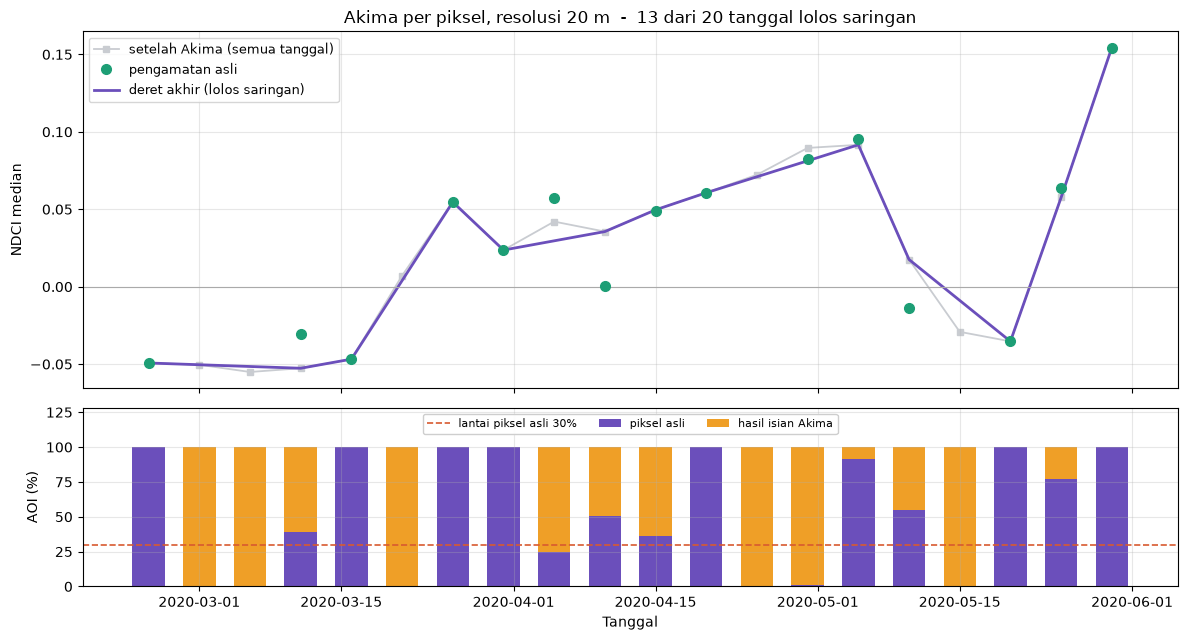


(Pemeriksaan silang dilewati. Isi CSV_GEE untuk membandingkan.)


In [4]:
"""
=====================================================================
PIPELINE TIFF -> NDCI, DENGAN INTERPOLASI AKIMA PER PIKSEL   (v3)
=====================================================================
  0. Inventaris + cek grid sejajar
  1. DN -> reflektansi, turunkan ke resolusi hitung
  2. Masker awan dan air            <-- v3: blok 20 m dibuang bila ADA awan
  3. NDCI per piksel
  4. Susun TUMPUKAN  (n_tanggal, tinggi, lebar), lubang awan = NaN
  5. AKIMA per piksel menembus sumbu waktu
  6. Agregasi per tanggal, DUA versi: asli dan terisi
  7. Saringan mutu                  <-- v3: lantai piksel ASLI, bukan piksel terisi
  8. Fitur turunan

PERUBAHAN v2 -> v3 (semuanya ketahuan saat diuji pada 20 TIFF asli):
  (1) MIN_VALID dulu dikenakan pada pct_terisi saat PAKAI_ISI=True.
      pct_terisi hampir selalu 100 % setelah Akima, jadi saringan itu
      TIDAK PERNAH membuang apa pun. Tanggal 100 % awan pun lolos.
      v3 memakai dua lantai terpisah: MIN_ASLI (piksel sungguhan) dan
      MIN_TERISI (kelengkapan setelah isian).
  (2) SCL dulu diturunkan dengan mengambil piksel sudut tiap blok 2x2.
      Reflektansi blok itu rata-rata 4 piksel, jadi blok yang 3/4 awan
      bisa lolos hanya karena sudutnya kebetulan bersih.
      v3: blok dibuang bila ADA satu saja piksel awan di dalamnya.
  (3) Tanggal yang ditolak kini diberi kolom 'alasan', bukan hilang
      diam-diam lewat b3_med = NaN.

Keluaran:
  ndci_deret_waktu.csv   semua tanggal + kolom 'alasan' + 'lolos'
  ndci_fitur_model.csv   hanya tanggal lolos, siap masuk model

PERSIAPAN:  pip install rasterio numpy pandas matplotlib scipy
=====================================================================
"""

import glob
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio import Affine
from rasterio.features import geometry_mask
from rasterio.warp import transform_geom
from scipy.interpolate import Akima1DInterpolator

# ======================== PENGATURAN ========================
FOLDER        = "geotiff2020-0225-0531"
SKALA_TIFF    = 10
SKALA_HITUNG  = 20
CSV_GEE       = ""

# ---- tombol masker, SAMAKAN dengan skrip GEE ----
SCL_DIBUANG   = [1, 8, 9, 10]
BUANG_SCL3    = False
BUANG_SCL7    = False
AMBANG_MNDWI  = -0.05
CARA_SCL      = "apapun"   # "apapun" = blok 20 m dibuang bila ADA awan  <- dianjurkan
                           # "sudut"  = perilaku lama, ambil piksel sudut blok

# ---- TAHAP 5: interpolasi Akima per piksel ----
PAKAI_AKIMA   = True
MIN_TITIK     = 5     # minimal observasi sah per piksel
MAKS_GAP_ISI  = 30    # hari. Jarak antar dua pengamatan pengapit lubang
BATAS_NDCI    = 0.6   # hasil isian di luar +/- ini dibuang

# ---- saringan mutu per tanggal (tahap 7) ----
MIN_ASLI      = 0.30  # lantai PIKSEL SUNGGUHAN. Inti perbaikan v3.
MIN_TERISI    = 0.70  # lantai kelengkapan setelah isian (hanya bila PAKAI_ISI)
MAKS_B3       = 0.15
PAKAI_ISI     = True  # True = deret akhir memakai nilai hasil isian

# ---- fitur model (tahap 8) ----
MAKS_GAP      = 20
# ============================================================

AOI = {
    "type": "Polygon",
    "coordinates": [[
        [112.8371613, -7.1632929], [112.8396659, -7.1646556], [112.8422513, -7.1650965],
        [112.8445134, -7.1657779], [112.8460889, -7.1662188], [112.8487954, -7.1659382],
        [112.8503305, -7.1654172], [112.8520271, -7.1656977], [112.8530370, -7.1660184],
        [112.8542893, -7.1650564], [112.8563899, -7.1643350], [112.8589753, -7.1636135],
        [112.8600660, -7.1639342], [112.8607931, -7.1632127], [112.8632977, -7.1630524],
        [112.8655895, -7.1638540], [112.8683365, -7.1648961], [112.8721741, -7.1661787],
        [112.8781527, -7.1691447], [112.8798610, -7.1707479], [112.8816385, -7.1716296],
        [112.8843450, -7.1727519], [112.8863648, -7.1743150], [112.8884250, -7.1759983],
        [112.8903640, -7.1780023], [112.8923350, -7.1790043], [112.8956071, -7.1794853],
        [112.8972633, -7.1802869], [112.8991619, -7.1805674], [112.9019089, -7.1809281],
        [112.9041711, -7.1811686], [112.9055849, -7.1806877], [112.9074835, -7.1807277],
        [112.9062313, -7.1878287], [112.8898708, -7.1846625], [112.8729405, -7.1757248],
        [112.8625804, -7.1708685], [112.8490309, -7.1728324], [112.8350134, -7.1695058],
        [112.8371613, -7.1632929]
    ]]
}

FAKTOR = max(1, int(round(SKALA_HITUNG / SKALA_TIFF)))


def turunkan(a, f):
    """Rata-rata blok f x f. Untuk reflektansi."""
    if f == 1:
        return a
    h, w = a.shape
    h2, w2 = (h // f) * f, (w // f) * f
    return a[:h2, :w2].reshape(h2 // f, f, w2 // f, f).mean(axis=(1, 3))


def awan_blok(scl10, f, cara):
    """SCL resolusi asli -> masker awan pada resolusi hitung.

    SCL itu KELAS, tidak boleh dirata-rata. Dua pilihan:
      'apapun' : blok dianggap awan bila ada satu piksel awan di dalamnya.
                 Konsisten dengan reflektansi yang dirata-rata sebelum
                 dipakai, sehingga tidak ada awan yang ikut terhitung.
      'sudut'  : ambil piksel kiri-atas blok. Lebih longgar, bisa bocor.
    """
    buang = list(SCL_DIBUANG)
    if BUANG_SCL3:
        buang.append(3)
    if BUANG_SCL7:
        buang.append(7)
    kotor = np.isin(scl10, buang)
    if f == 1:
        return kotor
    h, w = kotor.shape
    h2, w2 = (h // f) * f, (w // f) * f
    blok = kotor[:h2, :w2].reshape(h2 // f, f, w2 // f, f)
    return blok.any(axis=(1, 3)) if cara == "apapun" else blok[:, 0, :, 0]


# ==================== TAHAP 0 ====================
berkas = sorted(glob.glob(os.path.join(FOLDER, "S2_kwanyar_*.tif")))
if not berkas:
    raise SystemExit(f"Tidak ada S2_kwanyar_*.tif di '{FOLDER}'. Perbaiki FOLDER.")

print("=" * 72)
print("TAHAP 0 - INVENTARIS DAN PEMERIKSAAN GRID")
print("=" * 72)
bentuk, trans, crs_set = set(), set(), set()
for p in berkas:
    with rasterio.open(p) as s:
        bentuk.add((s.height, s.width))
        trans.add(tuple(np.round(np.array(s.transform)[:6], 6)))
        crs_set.add(str(s.crs))
        n_band = s.count
        nama_band = s.descriptions
print(f"Jumlah berkas : {len(berkas)}   |   band: {n_band}   |   CRS: {crs_set}")
print(f"Nama band     : {nama_band}")
print(f"Grid          : {'SEJAJAR' if len(bentuk)==1 and len(trans)==1 else '!! TIDAK SEJAJAR'}")
if len(bentuk) > 1 or len(trans) > 1:
    raise SystemExit("Grid tidak sejajar. Ekspor ulang dengan crs dan scale yang sama.")
if n_band < 6:
    raise SystemExit(f"Butuh 6 band B2,B3,B4,B5,B11,SCL. Berkas ini hanya {n_band}.")

with rasterio.open(berkas[0]) as s:
    H, W, tr_asli, crs = s.height, s.width, s.transform, s.crs
tr = tr_asli * Affine.scale(FAKTOR, FAKTOR)
Hh, Ww = H // FAKTOR, W // FAKTOR
di_dalam = geometry_mask([transform_geom("EPSG:4326", crs, AOI)],
                         out_shape=(Hh, Ww), transform=tr, invert=True)
PX_AOI = int(di_dalam.sum())
print(f"Resolusi hitung : {SKALA_HITUNG} m   |   larik {Hh} x {Ww}")
print(f"Piksel dalam AOI: {PX_AOI:,}  ->  {PX_AOI*SKALA_HITUNG**2/1e4:.1f} ha")

# peringatan bila pemotongan baris/kolom ganjil memakan AOI
if H % FAKTOR or W % FAKTOR:
    penuh = geometry_mask([transform_geom("EPSG:4326", crs, AOI)],
                          out_shape=(H, W), transform=tr_asli, invert=True)
    sisa = penuh[(H // FAKTOR) * FAKTOR:, :].sum() + penuh[:, (W // FAKTOR) * FAKTOR:].sum()
    print(f"Catatan: tinggi/lebar tidak habis dibagi {FAKTOR}. "
          f"Piksel AOI yang terpotong di tepi: {int(sisa)}")


# ============ TAHAP 1-4: SUSUN TUMPUKAN ============
print("\n" + "=" * 72)
print("TAHAP 1-4 - REFLEKTANSI, MASKER, NDCI, SUSUN TUMPUKAN")
print("=" * 72)
print(f"Masker SCL: buang {SCL_DIBUANG}"
      f"{' +3' if BUANG_SCL3 else ''}{' +7' if BUANG_SCL7 else ''}"
      f"   |   penurunan SCL: '{CARA_SCL}'\n")

N = len(berkas)
tumpuk = np.full((N, Hh, Ww), np.nan, dtype="float32")
tanggal, meta = [], []

for i, p in enumerate(berkas):
    tgl = os.path.basename(p).replace("S2_kwanyar_", "").replace(".tif", "")
    with rasterio.open(p) as s:
        a = s.read().astype("float32")

    b3  = turunkan(a[1], FAKTOR) / 10000.0
    b4  = turunkan(a[2], FAKTOR) / 10000.0
    b5  = turunkan(a[3], FAKTOR) / 10000.0
    b11 = turunkan(a[4], FAKTOR) / 10000.0
    awan = awan_blok(a[5].astype("int16"), FAKTOR, CARA_SCL)

    with np.errstate(divide="ignore", invalid="ignore"):
        mndwi = (b3 - b11) / (b3 + b11)
        ndci  = (b5 - b4) / (b5 + b4)
        ndgr  = (b3 - b4) / (b3 + b4)

    sah   = (~awan) & (mndwi > AMBANG_MNDWI)
    pakai = sah & np.isfinite(ndci)
    tumpuk[i] = np.where(pakai, ndci, np.nan).astype("float32")

    dlm = di_dalam & pakai
    tanggal.append(tgl)
    meta.append(dict(date=tgl, n_asli=int(dlm.sum()),
                     pct_awan=float((awan & di_dalam).mean()),
                     b3_med=float(np.median(b3[dlm])) if dlm.any() else np.nan,
                     ndgr_med=float(np.median(ndgr[dlm])) if dlm.any() else np.nan))
    tanda = "  <-- tidak ada pengamatan sah" if dlm.sum() == 0 else ""
    print(f"  {tgl}  piksel sah dalam AOI: {int(dlm.sum()):6,}  "
          f"({dlm.sum()/PX_AOI*100:5.1f}%)   awan {meta[-1]['pct_awan']*100:5.1f}%{tanda}")

tanggal = pd.to_datetime(tanggal)
urut = np.argsort(tanggal.values)
tumpuk, tanggal = tumpuk[urut], tanggal[urut]
meta = [meta[k] for k in urut]
t_hari = (tanggal - tanggal[0]).days.values.astype("float64")

print(f"\nTumpukan terbentuk: {tumpuk.shape}  ({tumpuk.nbytes/1e6:.1f} MB)")
jeda = np.diff(t_hari)
print(f"Rentang waktu     : {tanggal[0].date()} .. {tanggal[-1].date()}  "
      f"({len(tanggal)} tanggal, jeda {int(jeda.min())}-{int(jeda.max())} hari)")
lubang = np.isnan(tumpuk[:, di_dalam])
print(f"Lubang di dalam AOI: {lubang.sum():,} dari {lubang.size:,} ({lubang.mean()*100:.1f}%)")


# ============ TAHAP 5: AKIMA PER PIKSEL ============
print("\n" + "=" * 72)
print("TAHAP 5 - INTERPOLASI AKIMA PER PIKSEL MENEMBUS WAKTU")
print("=" * 72)

terisi = np.zeros_like(tumpuk, dtype=bool)
rekam_jarak = []

if not PAKAI_AKIMA:
    print("  Dilewati (PAKAI_AKIMA = False)")
elif N < MIN_TITIK:
    print(f"  Dilewati: hanya {N} tanggal, butuh minimal {MIN_TITIK}")
else:
    if N < 30:
        print(f"  PERINGATAN: hanya {N} tanggal. Cukup untuk menguji kode,")
        print("  belum cukup untuk menarik kesimpulan ilmiah.\n")

    ys, xs = np.where(di_dalam)
    t0 = time.time()
    n_diisi = n_lewat_titik = n_lewat_gap = n_lewat_batas = 0

    for k in range(len(ys)):
        r, c = ys[k], xs[k]
        seri = tumpuk[:, r, c]
        ada = np.isfinite(seri)
        n_ada = int(ada.sum())

        if n_ada < MIN_TITIK:
            n_lewat_titik += 1
            continue
        if n_ada == N:
            continue

        t_ada = t_hari[ada]
        target = (~ada) & (t_hari >= t_ada[0]) & (t_hari <= t_ada[-1])  # tanpa ekstrapolasi
        if not target.any():
            continue

        idx = np.searchsorted(t_ada, t_hari[target])
        panjang = t_ada[idx] - t_ada[idx - 1]
        boleh = panjang <= MAKS_GAP_ISI
        n_lewat_gap += int((~boleh).sum())
        if not boleh.any():
            continue
        pos = np.where(target)[0][boleh]

        nilai = Akima1DInterpolator(t_ada, seri[ada])(t_hari[pos])

        wajar = np.abs(nilai) <= BATAS_NDCI
        n_lewat_batas += int((~wajar).sum())
        pos, nilai = pos[wajar], nilai[wajar]
        if len(pos) == 0:
            continue

        tumpuk[pos, r, c] = nilai
        terisi[pos, r, c] = True
        n_diisi += len(pos)
        rekam_jarak.append(panjang[boleh][wajar])

    dt = time.time() - t0
    print(f"  Piksel diproses       : {len(ys):,}")
    print(f"  Nilai berhasil diisi  : {n_diisi:,}")
    print(f"  Dilewati, titik kurang: {n_lewat_titik:,} piksel")
    print(f"  Dilewati, jarak > {MAKS_GAP_ISI}h: {n_lewat_gap:,} nilai")
    print(f"  Dilewati, di luar +/-{BATAS_NDCI}: {n_lewat_batas:,} nilai")
    print(f"  Waktu                 : {dt:.1f} detik")
    if rekam_jarak:
        jr = np.concatenate(rekam_jarak)
        print("\n  Jarak antar pengamatan pengapit tiap nilai isian:")
        for b in (5, 10, 15, 20, 30):
            print(f"    <= {b:2d} hari : {(jr <= b).mean()*100:5.1f}%")
        print(f"    median {np.median(jr):.0f} hari, maksimum {jr.max():.0f} hari")
        print("  Makin jauh pengapitnya, makin lemah dasar nilai isian itu.")
    sisa = np.isnan(tumpuk[:, di_dalam])
    print(f"\n  Lubang tersisa        : {sisa.sum():,} ({sisa.mean()*100:.1f}%)")


# ============ TAHAP 6: AGREGASI, DUA VERSI ============
print("\n" + "=" * 72)
print("TAHAP 6 - AGREGASI PER TANGGAL (asli vs terisi)")
print("=" * 72)

baris = []
for i, tgl in enumerate(tanggal):
    lap, isi = tumpuk[i], terisi[i]
    asli_ok  = di_dalam & np.isfinite(lap) & (~isi)
    semua_ok = di_dalam & np.isfinite(lap)
    m = meta[i]
    baris.append(dict(
        date=tgl,
        ndci_med_asli=float(np.median(lap[asli_ok])) if asli_ok.any() else np.nan,
        ndci_med_isi=float(np.median(lap[semua_ok])) if semua_ok.any() else np.nan,
        ndci_std=float(np.std(lap[semua_ok])) if semua_ok.any() else np.nan,
        ndci_p10=float(np.percentile(lap[semua_ok], 10)) if semua_ok.any() else np.nan,
        ndci_p90=float(np.percentile(lap[semua_ok], 90)) if semua_ok.any() else np.nan,
        ndgr_med=m["ndgr_med"], b3_med=m["b3_med"],
        n_asli=int(asli_ok.sum()), n_isi=int((di_dalam & isi).sum()),
        n_total=int(semua_ok.sum()), px_aoi=PX_AOI,
        pct_valid=asli_ok.sum() / PX_AOI,
        pct_terisi=semua_ok.sum() / PX_AOI,
        pct_awan=m["pct_awan"],
    ))

mentah = pd.DataFrame(baris).sort_values("date").reset_index(drop=True)
mentah["selisih"] = mentah.ndci_med_isi - mentah.ndci_med_asli
# berapa bagian dari peta akhir yang sebenarnya hasil tebakan
mentah["porsi_isian"] = mentah.n_isi / mentah.n_total.replace(0, np.nan)

print(mentah[["date", "ndci_med_asli", "ndci_med_isi", "selisih",
              "n_asli", "n_isi", "pct_valid", "porsi_isian"]]
      .assign(date=lambda x: x.date.dt.strftime("%Y-%m-%d")).round(4).to_string(index=False))

ef = mentah.selisih.abs()
print(f"\nEfek pengisian pada nilai median (hanya tanggal yang punya keduanya):")
print(f"  rerata |selisih| : {ef.mean():.5f}")
print(f"  maksimum         : {ef.max():.5f}")
print(f"  tanggal berubah  : {(ef > 0.001).sum()} dari {ef.notna().sum()}")


# ==================== TAHAP 7: SARINGAN ====================
print("\n" + "=" * 72)
print("TAHAP 7 - SARINGAN MUTU")
print("=" * 72)
KOL = "ndci_med_isi" if PAKAI_ISI else "ndci_med_asli"
print(f"  Kolom dipakai : {KOL}")
print(f"  Lantai piksel ASLI   (pct_valid)  >= {MIN_ASLI}")
if PAKAI_ISI:
    print(f"  Lantai kelengkapan   (pct_terisi) >= {MIN_TERISI}")
print(f"  Batas kekeruhan      (b3_med)     <  {MAKS_B3}")
print("\n  CATATAN PENTING. Lantai pct_valid inilah yang mencegah tanggal")
print("  tertutup awan total ikut masuk. Setelah Akima, pct_terisi hampir")
print("  selalu 100 % sehingga tidak bisa dipakai sebagai penjaga mutu.\n")


def nilai_alasan(r):
    if pd.isna(r[KOL]):
        return "nilai kosong"
    if r.pct_valid < MIN_ASLI:
        return f"piksel asli {r.pct_valid*100:.1f}% < {MIN_ASLI*100:.0f}%"
    if PAKAI_ISI and r.pct_terisi < MIN_TERISI:
        return f"kelengkapan {r.pct_terisi*100:.1f}% < {MIN_TERISI*100:.0f}%"
    if not (r.b3_med < MAKS_B3):
        return f"b3_med {r.b3_med:.4f} >= {MAKS_B3}"
    return ""


mentah["alasan"] = mentah.apply(nilai_alasan, axis=1)
mentah["lolos"] = mentah.alasan == ""

for _, r in mentah.iterrows():
    cap = "LOLOS" if r.lolos else f"tolak  ({r.alasan})"
    print(f"  {r.date.strftime('%Y-%m-%d')}  {cap}")

d = mentah[mentah.lolos].copy().reset_index(drop=True)
d["ndci_med"] = d[KOL]
print(f"\n  {len(mentah)} tanggal  ->  {len(d)} lolos  ({len(mentah)-len(d)} ditolak)")
if len(d):
    print(f"  Porsi isian pada tanggal yang lolos: "
          f"rerata {d.porsi_isian.mean()*100:.1f}%, maksimum {d.porsi_isian.max()*100:.1f}%")

mentah.to_csv("ndci_deret_waktu.csv", index=False)
print("  Tersimpan: ndci_deret_waktu.csv  (SEMUA tanggal, lihat kolom 'lolos' dan 'alasan')")


# ==================== TAHAP 8: FITUR ====================
print("\n" + "=" * 72)
print("TAHAP 8 - FITUR TURUNAN")
print("=" * 72)
if len(d) < 3:
    print(f"  Hanya {len(d)} tanggal lolos. Terlalu sedikit untuk membuat fitur.")
    siap = d.iloc[0:0].copy()
else:
    f = d.copy()
    f["gap_days"]     = f.date.diff().dt.days
    f["ndci_lag1"]    = f.ndci_med.shift(1)
    f["ndci_lag2"]    = f.ndci_med.shift(2)
    f["ndci_rate"]    = (f.ndci_med - f.ndci_lag1) / f.gap_days
    f["ndci_next"]    = f.ndci_med.shift(-1)
    f["horizon_days"] = -f.date.diff(-1).dt.days
    doy = f.date.dt.dayofyear
    f["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    f["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    siap = f[(f.gap_days <= MAKS_GAP) & (f.horizon_days <= MAKS_GAP)].dropna(
        subset=["ndci_lag1", "ndci_next"]).reset_index(drop=True)
    print(f"  Baris siap model (jeda <= {MAKS_GAP} hari): {len(siap)} dari {len(f)}")
siap.to_csv("ndci_fitur_model.csv", index=False)
print("  Tersimpan: ndci_fitur_model.csv")


# ==================== GRAFIK ====================
if len(mentah) > 1:
    fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                           gridspec_kw={"height_ratios": [2, 1]})
    ax[0].plot(mentah.date, mentah.ndci_med_isi, "s-", ms=4, lw=1.3,
               color="#C9CCD1", zorder=1, label="setelah Akima (semua tanggal)")
    ax[0].plot(mentah.date, mentah.ndci_med_asli, "o", ms=7,
               color="#1D9E75", zorder=3, label="pengamatan asli")
    if len(d):
        ax[0].plot(d.date, d.ndci_med, "-", lw=2, color="#6B4FBB",
                   zorder=2, label="deret akhir (lolos saringan)")
    ax[0].axhline(0, color="#aaa", lw=0.8)
    ax[0].set_ylabel("NDCI median")
    ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)
    ax[0].set_title(f"Akima per piksel, resolusi {SKALA_HITUNG} m  -  "
                    f"{len(d)} dari {len(mentah)} tanggal lolos saringan")

    ax[1].bar(mentah.date, mentah.pct_valid * 100, width=3.2,
              color="#6B4FBB", label="piksel asli")
    ax[1].bar(mentah.date, (mentah.pct_terisi - mentah.pct_valid) * 100, width=3.2,
              bottom=mentah.pct_valid * 100, color="#EF9F27", label="hasil isian Akima")
    ax[1].axhline(MIN_ASLI * 100, color="#D85A30", ls="--", lw=1.2,
                  label=f"lantai piksel asli {MIN_ASLI*100:.0f}%")
    ax[1].set_ylabel("AOI (%)"); ax[1].set_xlabel("Tanggal")
    ax[1].set_ylim(0, 128)
    ax[1].legend(fontsize=8, ncol=3, loc="upper center", framealpha=0.95)
    ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


# ============ PEMERIKSAAN SILANG DENGAN GEE ============
if CSV_GEE and os.path.exists(CSV_GEE):
    print("\n" + "=" * 72)
    print("PEMERIKSAAN SILANG DENGAN HASIL GEE")
    print("=" * 72)
    g = pd.read_csv(CSV_GEE); g["date"] = pd.to_datetime(g["date"])
    m = mentah.merge(g[["date", "ndci_med"]], on="date").dropna(
        subset=["ndci_med_asli", "ndci_med"])
    if len(m) >= 2:
        sel = m.ndci_med_asli - m.ndci_med
        print(f"  Tanggal beririsan : {len(m)}")
        print(f"  Korelasi          : {np.corrcoef(m.ndci_med_asli, m.ndci_med)[0,1]:+.4f}")
        print(f"  Bias (lokal-gee)  : {sel.mean():+.5f}")
        print(f"  MAE               : {sel.abs().mean():.5f}")
        print("\n  Dibandingkan kolom ASLI, karena GEE tidak melakukan pengisian.")
        print("  MAE di bawah 0,01 berarti kedua jalur konsisten.")
    else:
        print("  Tanggal beririsan kurang dari 2, perbandingan dilewati.")
else:
    print("\n(Pemeriksaan silang dilewati. Isi CSV_GEE untuk membandingkan.)")
